# Comparer CatBoost sans et avec feature engineering

**Partie 1 : déclarer** les fonctions communes et la classe de transformation.

**Partie 2 : lancer** les deux expériences sur les mêmes observations et les mêmes mois, puis comparer leurs résultats.

La cible reste le churn à 30 jours. `region`, `dept`, l’âge et l’intervention de rétention sont exclus. Les résultats restent en mémoire. Les cellules sont préparées mais ne sont pas exécutées dans cette modification.


## Partie 1.1 — Imports et configuration commune

Même calendrier et mêmes paramètres pour les deux modèles. Le catalogue centralise les variables créées et leur type.


In [18]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch
from catboost import CatBoostClassifier, EFstrType
from IPython.display import display
from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    precision_recall_curve,
)

# Ouvrir le notebook depuis la racine du projet ou depuis notebooks/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from settings import settings

SEED = 42
DATA_PATH = settings.DATA_PATH
MODEL_FEATURES = [
    "contract",
    "channel",
    "monthly_fee",
    "data_gb",
    "support_calls_3m",
    "late_payments",
    "nps",
    "last_invoice_amount",
]
CATEGORICAL_FEATURES = ["contract", "channel"]
NUMERIC_FEATURES = [
    "monthly_fee",
    "data_gb",
    "support_calls_3m",
    "late_payments",
    "nps",
    "last_invoice_amount",
]

LABEL_DELAY = pd.Timedelta(30, unit="D")
VALIDATION_MONTHS = ("2024-07", "2024-08", "2024-09")
TEST_MONTHS = ("2024-10", "2024-11")

# Une seule déclaration du nom et du type de chaque variable créée.
FEATURE_CATALOG = {
    "tenure_days": "numeric",
    "tenure_months": "numeric",
    "tenure_band": "categorical",
    "monthly_fee_change_pct": "numeric",
    "usage_drop_pct": "numeric",
    "billing_deviation_pct": "numeric",
    "monthly_fee_band": "categorical",
    "late_payment_alert": "numeric",
    "support_payment_alert": "numeric",
    "fee_band_support": "categorical",
    "regular_usage_gb": "numeric",
    "satisfaction_segment": "categorical",
}


## Partie 1.2 — Préparation et split temporel

La lecture et le nettoyage ne sont écrits qu’une fois. Les snapshots sans cible restent disponibles comme historique. À chaque scoring, les labels du train **et** de la validation interne doivent être disponibles à J+30.

| Mois prédit | Train | Early stopping | Rôle |
|---|---|---|---|
| Juillet | Janvier–mai | Juin | Validation |
| Août | Janvier–juin | Juillet | Validation |
| Septembre | Janvier–juillet | Août | Validation |
| Octobre | Janvier–août | Septembre | Test |
| Novembre | Janvier–septembre | Octobre | Test |

Si J+30 tombe le jour du scoring, les labels sont supposés chargés avant le fit. Octobre peut servir à l’early stopping de novembre une fois ses labels connus ; cela fait partie du protocole fixé. Les mois ayant déjà été consultés, le bilan reste rétrospectif.


In [19]:
def prepare_data(path: Path) -> pd.DataFrame:
    """Lire et nettoyer les données une seule fois pour les deux expériences."""
    data = pd.read_csv(path, dtype={"customer_id": "string"})
    data = data.drop(columns=["region", "dept"], errors="ignore")
    required = ["customer_id", "snapshot_date", "signup_date", "churn"] + MODEL_FEATURES
    missing = sorted(set(required) - set(data.columns))
    if missing:
        raise ValueError(f"Colonnes absentes : {missing}")

    data["customer_id"] = data["customer_id"].str.strip()
    data["snapshot_date"] = pd.to_datetime(data["snapshot_date"], errors="coerce")
    if data["snapshot_date"].isna().any() or data["customer_id"].isna().any() or data["customer_id"].eq("").any():
        raise ValueError("Identifiant client ou date de snapshot invalide.")
    for column in CATEGORICAL_FEATURES:
        data[column] = data[column].astype("string").str.strip().str.strip("\"'").str.lower()
    for column in NUMERIC_FEATURES + ["churn"]:
        data[column] = pd.to_numeric(data[column], errors="coerce")
    if not data["churn"].dropna().isin([0, 1]).all():
        raise ValueError("La cible churn doit être binaire.")

    raw_count = len(data)
    data = data.drop_duplicates().copy()
    copies_removed = raw_count - len(data)
    data["_month"] = data["snapshot_date"].dt.to_period("M")
    ambiguous = data.duplicated(["customer_id", "_month"], keep=False)
    ambiguous_count = int(ambiguous.sum())
    data = data.loc[~ambiguous].drop(columns="_month").copy()

    for column in NUMERIC_FEATURES:
        values = data[column]
        data[column] = values.where((values >= 0) & np.isfinite(values))
    data["nps"] = data["nps"].where(data["nps"].between(0, 10))
    if data.empty or data["churn"].notna().sum() == 0:
        raise ValueError("Aucune observation étiquetée exploitable.")
    print(f"{len(data):,} lignes conservées ; {copies_removed} copies retirées ; {ambiguous_count} lignes ambiguës exclues.")
    return data


def build_monthly_fold(data: pd.DataFrame, scoring_date: pd.Timestamp) -> dict:
    """Séparer le passé en train, validation interne et mois à prédire."""
    score_month = scoring_date.to_period("M")
    early_stop_month = score_month - 1
    months = data["snapshot_date"].dt.to_period("M")
    label_dates = data["snapshot_date"] + LABEL_DELAY
    labels_available = label_dates <= scoring_date

    train = data.loc[(months < early_stop_month) & labels_available].copy()
    early_stop = data.loc[(months == early_stop_month) & labels_available].copy()
    score = data.loc[months == score_month].copy()

    # Toutes les cibles du mois de validation interne doivent être connues.
    expected_count = (months == early_stop_month).sum()
    if len(early_stop) != expected_count:
        raise ValueError("Labels de validation interne pas tous disponibles à cette date.")
    if train.empty or train["churn"].nunique() != 2:
        raise ValueError("Le train doit contenir les deux classes.")
    if early_stop.empty or early_stop["churn"].nunique() != 2:
        raise ValueError("La validation interne doit contenir les deux classes.")
    if score.empty or (score["snapshot_date"] > scoring_date).any():
        raise ValueError("Mois à prédire vide ou contenant une date future.")

    assert (train["snapshot_date"] + LABEL_DELAY <= scoring_date).all()
    assert (early_stop["snapshot_date"] + LABEL_DELAY <= scoring_date).all()
    assert train["snapshot_date"].max() < early_stop["snapshot_date"].min()
    assert early_stop["snapshot_date"].max() < score["snapshot_date"].min()
    return {"train": train, "early_stop": early_stop, "score": score}


## Partie 1.3 — Classe de transformation

L’hypothèse à tester est qu’une hausse du tarif, une baisse d’usage ou un historique de retard peuvent être associés au churn. On n’affirme pas que le prix cause les appels ou le départ.

| Variable | Calcul / groupes | Interprétation |
|---|---|---|
| `tenure_days` | `(snapshot_date − signup_date).days` | Ancienneté exacte en jours, conservée pour lecture |
| `tenure_months` | `tenure_days / 30.4375` | Ancienneté approximative en mois, utilisée par le modèle |
| `tenure_band` | `[0,3[`, `[3,6[`, `[6,12[`, `[12,24[`, `[24,48[`, `[48,+∞[` mois | Étape de la relation client |
| `monthly_fee_change_pct` | `100 × (F_t − F_t−1) / F_t−1` | Évolution du montant mensuel enregistré |
| `monthly_fee_band` | `[0,40[`, `[40,70[`, `[70,+∞[` euros | Tranches tarifaires fixes, à discuter avec le métier |
| `late_payment_alert` | `1[late_payments > 0]` | Alerte sur la présence d’au moins un retard enregistré |
| `support_payment_alert` | `1[support_calls_3m > 0 ET late_payments > 0]` | Support récent combiné à un historique de retard |
| `fee_band_support` | Tranche tarifaire + support présent/absent | Segmenter les sollicitations selon le niveau de prix |
| `usage_drop_pct` | `100 × max(0, 1 − U_t / médiane(U_t−1, U_t−2, U_t−3))` | Baisse par rapport à l’usage récent |
| `billing_deviation_pct` | `100 × (I_t − F_t) / F_t` | Écart entre facture et mensualité |
| `regular_usage_gb` | `médiane(U_t−2, U_t−1, U_t)` sur trois mois consécutifs | Niveau récent d’usage régulier, en Go |
| `satisfaction_segment` | `[0,6]`, `]6,8]`, `]8,10]` | Niveau de satisfaction renseigné au snapshot |

Par défaut, douze colonnes créées, dont onze utilisées avec les huit originales : **19 prédicteurs**. Les jours restent visibles mais ne doublonnent pas les mois dans le modèle. Les bandes sont des catégories ; elles ne sont pas des tranches d’âge.

Les seuils de prix 40/70 € sont des hypothèses de départ, pas des seuils appris sur le test. Un cumul de retards ne prouve pas un impayé encore ouvert : l’alerte décrit l’historique connu. Les baisses observées de ce compteur restent à clarifier. Le croisement prix/support est un segment descriptif, pas une preuve de causalité.

Les valeurs invalides ou inconnues restent manquantes, y compris les alertes. Les variations exigent des mois consécutifs du même client, avec référence strictement positive. Aucun label n’entre dans les transformations.


`regular_usage_gb` résume le volume habituellement consommé et atténue un pic isolé. Trois usages nuls donnent 0 ; un mois absent ou une mesure invalide donne une valeur manquante. Sans quota data du forfait, on ne peut pas calculer son taux d’utilisation ni affirmer une dépendance à l’offre.

Le segment de satisfaction utilise seulement la note courante valide. Une note absente reste inconnue : elle n’est pas remplacée par une satisfaction faible. Les bornes 6/8 définissent des groupes de lecture ; leur apport doit être vérifié sur validation.

`region` et `dept` sont retirés des deux versions du modèle. `last_invoice_amount` reste un prédicteur, sous l’hypothèse qu’il est bien connu au snapshot. La cible reste le churn à **30 jours** ; trois mois désignent ici une fenêtre d’usage, pas un nouvel horizon de prédiction. Prédire à 90 jours demanderait une cible fiable à 90 jours.


Pour ajouter une variable : écrire sa méthode, l’appeler dans `transform`, puis ajouter son nom et son type dans `FEATURE_CATALOG`. Elle sera ensuite proposée au modèle enrichi automatiquement. `EXCLUDED_FEATURES`, dans la partie 2, permet de la désactiver sans supprimer son calcul.


In [20]:
class ChurnFeatureEngineer:
    def add_tenure(self, data: pd.DataFrame) -> pd.DataFrame:
        days = (data["snapshot_date"] - data["signup_date"]).dt.days
        data["tenure_days"] = days.where(days >= 0).astype(float)
        data["tenure_months"] = data["tenure_days"] / 30.4375
        data["tenure_band"] = pd.cut(
            data["tenure_months"],
            bins=[0, 3, 6, 12, 24, 48, np.inf],
            labels=["0–3 mois", "3–6 mois", "6–12 mois", "12–24 mois", "24–48 mois", "48 mois et plus"],
            right=False,
        ).astype("string")
        return data

    def add_fee_change(self, data: pd.DataFrame) -> pd.DataFrame:
        fee = data["monthly_fee"]
        previous_fee = fee.groupby(data["customer_id"]).shift(1)
        previous_month = data.groupby("customer_id")["_feature_month"].shift(1)
        consecutive = data["_feature_month"] - previous_month == 1
        reference = previous_fee.where(previous_fee > 0)
        data["monthly_fee_change_pct"] = (100 * (fee - reference) / reference).where(consecutive)
        return data

    def usage_history(self, data: pd.DataFrame, lags: list):
        """Construire une fenêtre d’usage du même client, sans mois manquants."""
        if min(lags) < 0:
            raise ValueError("Les décalages ne doivent jamais pointer vers le futur.")
        usage = data["data_gb"]
        clients = data["customer_id"]
        month = data["_feature_month"]
        values = []
        complete = usage.notna()
        for lag in lags:
            previous_usage = usage.groupby(clients).shift(lag)
            previous_month = month.groupby(clients).shift(lag)
            complete = complete & previous_usage.notna() & (month - previous_month == lag)
            values.append(previous_usage)
        return pd.concat(values, axis=1), complete

    def add_usage_drop(self, data: pd.DataFrame) -> pd.DataFrame:
        history, complete = self.usage_history(data, [1, 2, 3])
        reference = history.median(axis=1, skipna=False)
        reference = reference.where(reference > 0)
        drop = 100 * (1 - data["data_gb"] / reference)
        data["usage_drop_pct"] = drop.clip(lower=0).where(complete)
        return data

    def add_billing_deviation(self, data: pd.DataFrame) -> pd.DataFrame:
        fee = data["monthly_fee"].where(data["monthly_fee"] > 0)
        invoice = data["last_invoice_amount"]
        data["billing_deviation_pct"] = 100 * (invoice - fee) / fee
        return data

    def add_price_groups(self, data: pd.DataFrame) -> pd.DataFrame:
        # Seuils de départ à discuter avec le métier, fixés avant les tests.
        data["monthly_fee_band"] = pd.cut(
            data["monthly_fee"],
            bins=[0, 40, 70, np.inf],
            labels=["Moins de 40 €", "40 à moins de 70 €", "70 € et plus"],
            right=False,
        ).astype("string")
        return data

    def add_payment_alerts(self, data: pd.DataFrame) -> pd.DataFrame:
        payments = data["late_payments"]
        calls = data["support_calls_3m"]

        # Un retard connu déclenche l’alerte ; une valeur absente reste manquante.
        data["late_payment_alert"] = (payments > 0).astype(float)
        data.loc[payments.isna(), "late_payment_alert"] = np.nan

        # Présence simultanée de support récent et d’un historique de retard.
        data["support_payment_alert"] = ((calls > 0) & (payments > 0)).astype(float)
        missing = calls.isna() | payments.isna()
        data.loc[missing, "support_payment_alert"] = np.nan
        return data

    def add_price_support_group(self, data: pd.DataFrame) -> pd.DataFrame:
        calls = data["support_calls_3m"]
        support_status = pd.Series(pd.NA, index=data.index, dtype="string")
        support_status.loc[calls == 0] = "Sans appel support"
        support_status.loc[calls > 0] = "Avec appel support"
        data["fee_band_support"] = data["monthly_fee_band"] + " | " + support_status
        return data

    def add_regular_usage(self, data: pd.DataFrame) -> pd.DataFrame:
        # Mois courant et deux mois précédents.
        history, complete = self.usage_history(data, [0, 1, 2])
        data["regular_usage_gb"] = history.median(axis=1, skipna=False).where(complete)
        return data

    def add_satisfaction_segment(self, data: pd.DataFrame) -> pd.DataFrame:
        score = pd.to_numeric(data["nps"], errors="coerce")
        score = score.where(score.between(0, 10))
        data["satisfaction_segment"] = pd.cut(
            score,
            bins=[-0.1, 6, 8, 10],
            labels=["Faible (0–6)", "Intermédiaire (>6–8)", "Élevée (>8–10)"],
            right=True,
        ).astype("string")
        return data

    def transform(self, data: pd.DataFrame) -> pd.DataFrame:
        # Travailler sur une copie et mémoriser l’ordre initial des lignes.
        result = data.copy().reset_index(drop=True)
        result["snapshot_date"] = pd.to_datetime(result["snapshot_date"], errors="coerce")
        result["signup_date"] = pd.to_datetime(result["signup_date"], errors="coerce")
        if result["customer_id"].isna().any() or result["snapshot_date"].isna().any():
            raise ValueError("Identifiant ou date de snapshot manquant.")
        result["_row_order"] = np.arange(len(result))
        result["_feature_month"] = (
            result["snapshot_date"].dt.year * 12 + result["snapshot_date"].dt.month
        )
        if result.duplicated(["customer_id", "_feature_month"]).any():
            raise ValueError("Plusieurs snapshots du même client dans un mois.")
        result = result.sort_values(["customer_id", "snapshot_date"])
        for column in ["monthly_fee", "data_gb", "last_invoice_amount", "support_calls_3m", "late_payments"]:
            values = pd.to_numeric(result[column], errors="coerce")
            result[column] = values.where((values >= 0) & np.isfinite(values))

        result = self.add_tenure(result)
        result = self.add_fee_change(result)
        result = self.add_usage_drop(result)
        result = self.add_billing_deviation(result)
        result = self.add_price_groups(result)
        result = self.add_payment_alerts(result)
        result = self.add_price_support_group(result)
        result = self.add_regular_usage(result)
        result = self.add_satisfaction_segment(result)
        # Vérifier le catalogue et mettre les colonnes créées au bon format.
        for column, kind in FEATURE_CATALOG.items():
            if column not in result.columns:
                raise ValueError(f"La transformation de {column} n’a pas été appelée.")
            if kind == "numeric":
                values = pd.to_numeric(result[column], errors="coerce")
                result[column] = values.astype(float).replace([np.inf, -np.inf], np.nan)
            elif kind == "categorical":
                result[column] = result[column].astype("string")
            else:
                raise ValueError(f"Type de feature inconnu : {kind}")
        result = result.sort_values("_row_order")
        result = result.drop(columns=["_row_order", "_feature_month"])
        result.index = data.index
        return result


## Partie 1.4 — Entraînement, seuil et métriques

Les arguments sont explicites : données, mois, prédicteurs et catégories. Aucun accès à un ancien résultat global. Les poids sont calculés uniquement sur le train. Le seuil F1 est choisi sur validation et conservé pendant les tests. Les paramètres CatBoost sont écrits une seule fois dans `fit_predict_month`.


In [21]:
def make_matrix(
    part: pd.DataFrame, features: list, categorical_features: list,
) -> pd.DataFrame:
    """Mettre les colonnes choisies au format attendu par CatBoost."""
    x = part[features].copy()
    for column in categorical_features:
        x[column] = x[column].astype("string").fillna("__MISSING__").astype(str)
    for column in features:
        if column not in categorical_features:
            x[column] = x[column].astype(float)
    return x


def fit_predict_month(
    data: pd.DataFrame, month: str, features: list, categorical_features: list,
) -> dict:
    """Entraîner sur le passé, avec J+30, puis prédire un seul mois."""
    scoring_date = pd.Period(month, freq="M").end_time.normalize()
    parts = build_monthly_fold(data, scoring_date)
    train = parts["train"]
    early_stop = parts["early_stop"]
    score = parts["score"]

    X_train = make_matrix(train, features, categorical_features)
    X_early_stop = make_matrix(early_stop, features, categorical_features)
    X_score = make_matrix(score, features, categorical_features)
    y_train = train["churn"].to_numpy()
    y_early_stop = early_stop["churn"].to_numpy()

    # Donner le même poids total aux deux classes dans le train.
    count_0 = int((y_train == 0).sum())
    count_1 = int((y_train == 1).sum())
    class_weights = {
        0: len(y_train) / (2 * count_0),
        1: len(y_train) / (2 * count_1),
    }

    # Les mêmes paramètres sont utilisés pour les cinq mois.
    model = CatBoostClassifier(
        iterations=1800,
        depth=6,
        learning_rate=0.035,
        loss_function="Logloss",
        eval_metric="PRAUC:use_weights=false",
        custom_metric=["Logloss", "AUC"],
        l2_leaf_reg=5,
        random_seed=SEED,
        class_weights=class_weights,
        verbose=50,
        allow_writing_files=False,
        thread_count=-1,
    )

    print(f"\nMois prédit : {month} — poids des classes : {class_weights}")
    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features,
        eval_set=(X_early_stop, y_early_stop),
        early_stopping_rounds=120,
        use_best_model=True,
    )

    probabilities = np.asarray(model.predict_proba(X_score))[:, 1]
    predictions = score[["customer_id", "snapshot_date", "churn"]].copy()
    predictions["probability"] = probabilities
    predictions["scoring_month"] = month

    return {"model": model, "predictions": predictions, "class_weights": class_weights}


def choose_threshold(predictions: pd.DataFrame) -> float:
    """Choisir le seuil F1 uniquement sur les prédictions de validation."""
    precision, recall, thresholds = precision_recall_curve(
        predictions["churn"], predictions["probability"]
    )

    # Le dernier couple précision/rappel ne correspond à aucun seuil.
    threshold_rows = []
    for i in range(len(thresholds)):
        total = precision[i] + recall[i]
        f1 = 0.0
        if total > 0:
            f1 = 2 * precision[i] * recall[i] / total
        threshold_rows.append({"threshold": thresholds[i], "F1": f1})

    threshold_table = pd.DataFrame(threshold_rows)
    threshold_table = threshold_table.sort_values(["F1", "threshold"], ascending=False)
    return float(threshold_table.iloc[0]["threshold"])


def evaluate(y_true: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    predicted = (probability >= threshold).astype(int)
    # scikit-learn accepte 0 ; son annotation inférée indique seulement str.
    return {
        "Average Precision": average_precision_score(y_true, probability),
        "ROC-AUC": roc_auc_score(y_true, probability),
        "Logloss": log_loss(y_true, probability, labels=[0, 1]),
        "F1": f1_score(y_true, predicted, zero_division=0),  # pyright: ignore[reportArgumentType]
        "Precision": precision_score(y_true, predicted, zero_division=0),  # pyright: ignore[reportArgumentType]
        "Recall": recall_score(y_true, predicted, zero_division=0),  # pyright: ignore[reportArgumentType]
    }


## Partie 1.5 — Fonctions de comparaison

Chaque expérience garde son nom, ses colonnes, ses cinq modèles, ses prédictions et son seuil. Les mêmes fonctions traitent le modèle de référence et le modèle enrichi. Le lancement de la validation et celui des tests sont séparés.


In [22]:
def describe_splits(data: pd.DataFrame) -> pd.DataFrame:
    """Afficher le calendrier commun avant les entraînements."""
    rows = []
    for month in list(VALIDATION_MONTHS) + list(TEST_MONTHS):
        scoring_date = pd.Period(month, freq="M").end_time.normalize()
        parts = build_monthly_fold(data, scoring_date)
        role = "Validation"
        if month in TEST_MONTHS:
            role = "Test"
        rows.append({
            "mois_prédit": month, "rôle": role,
            "train_début": parts["train"]["snapshot_date"].min().date(),
            "train_fin": parts["train"]["snapshot_date"].max().date(),
            "early_stopping": parts["early_stop"]["snapshot_date"].max().date(),
            "n_train": len(parts["train"]), "n_prédictions": len(parts["score"]),
        })
    return pd.DataFrame(rows)


def run_validation(name: str, data: pd.DataFrame, features: list, categorical_features: list) -> dict:
    """Créer une expérience et choisir son seuil sur juillet–septembre seulement."""
    if not features or len(features) != len(set(features)):
        raise ValueError("La liste des prédicteurs doit être non vide et sans doublons.")
    forbidden = {"customer_id", "snapshot_date", "signup_date", "churn", "age", "age_band", "region", "dept", "retention_offer_declined"}
    if set(features) & forbidden:
        raise ValueError("Un prédicteur exclu figure dans la sélection.")
    if not set(categorical_features).issubset(features):
        raise ValueError("Une catégorie déclarée est absente des prédicteurs.")

    monthly_results = {}
    predictions = []
    print(f"\n=== {name} : validation ===")
    for month in VALIDATION_MONTHS:
        result = fit_predict_month(data, month, features, categorical_features)
        monthly_results[month] = result
        predictions.append(result["predictions"])

    validation_predictions = pd.concat(predictions, ignore_index=True)
    assert not validation_predictions.duplicated(["customer_id", "snapshot_date"]).any()
    first_test_date = pd.Period(TEST_MONTHS[0], freq="M").end_time.normalize()
    assert validation_predictions["snapshot_date"].max() + LABEL_DELAY <= first_test_date
    threshold = choose_threshold(validation_predictions)
    print(f"{name} — seuil choisi avant les tests : {threshold:.4f}")
    return {
        "name": name, "data": data, "features": features.copy(),
        "categorical_features": categorical_features.copy(),
        "monthly_results": monthly_results,
        "validation_predictions": validation_predictions, "threshold": threshold,
    }


def run_tests(experiment: dict) -> dict:
    """Ajouter octobre et novembre sans changer le seuil de l’expérience."""
    threshold_before_test = experiment["threshold"]
    predictions = []
    print(f"\n=== {experiment['name']} : test ===")
    for month in TEST_MONTHS:
        result = fit_predict_month(
            experiment["data"], month, experiment["features"], experiment["categorical_features"],
        )
        experiment["monthly_results"][month] = result
        predictions.append(result["predictions"])
    test_predictions = pd.concat(predictions, ignore_index=True)
    assert not test_predictions.duplicated(["customer_id", "snapshot_date"]).any()
    experiment["test_predictions"] = test_predictions
    assert experiment["threshold"] == threshold_before_test
    return experiment


def compare_experiments(experiments: list, stage: str) -> pd.DataFrame:
    """Comparer les mêmes métriques pour les deux modèles."""
    if stage == "Validation":
        key = "validation_predictions"
    elif stage == "Test":
        key = "test_predictions"
    else:
        raise ValueError("Choisir Validation ou Test.")
    rows = []
    for experiment in experiments:
        predictions = experiment[key]
        row = evaluate(
            predictions["churn"].to_numpy(), predictions["probability"].to_numpy(),
            experiment["threshold"],
        )
        row["Modèle"] = experiment["name"]
        row["Variables"] = len(experiment["features"])
        row["Seuil"] = experiment["threshold"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("Modèle")


def get_monthly_metrics(experiment: dict) -> pd.DataFrame:
    """Vérifier les scores mois par mois, pas uniquement leur moyenne."""
    rows = []
    for month, result in experiment["monthly_results"].items():
        predictions = result["predictions"]
        row = evaluate(
            predictions["churn"].to_numpy(), predictions["probability"].to_numpy(),
            experiment["threshold"],
        )
        row["Mois"] = month
        row["Meilleure itération"] = result["model"].best_iteration_
        rows.append(row)
    return pd.DataFrame(rows).set_index("Mois")


## Partie 1.6 — Graphiques réutilisables

Une seule fonction par graphique. Les matrices montrent l’effectif puis le pourcentage normalisé par classe réelle, avec une échelle commune de 0 à 100 %. L’importance native est globale : ni signe de l’effet, ni causalité, ni contribution individuelle. Une forte importance de deux colonnes n’est pas une preuve que le modèle est mauvais ; on vérifie l’apport par comparaison sur validation.


In [23]:
def plot_learning_curve(experiment: dict, month: str):
    """Afficher le train et la validation interne du modèle mensuel choisi."""
    model = experiment["monthly_results"][month]["model"]
    history = model.get_evals_result()
    fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
    ax.plot(history["learn"]["Logloss"], label="Train", color="#2563EB")
    ax.plot(history["validation"]["Logloss"], label="Validation interne", color="#E11D48")
    ax.set_title(f"{experiment['name']} — modèle de {month}")
    ax.set_xlabel("Itérations")
    ax.set_ylabel("Logloss pondérée")
    ax.legend()
    plt.show()
    return fig


def plot_confusion_matrices(experiment: dict):
    """Même rendu Matplotlib pour chaque expérience : effectif puis pourcentage."""
    labels = ["Non-churn (0)", "Churn (1)"]
    prediction_keys = ["validation_predictions", "test_predictions"]
    titles = ["Validation", "Test"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")

    for position in range(2):
        predictions = experiment[prediction_keys[position]]
        predicted = (predictions["probability"].to_numpy() >= experiment["threshold"]).astype(int)
        matrix = confusion_matrix(predictions["churn"], predicted, labels=[0, 1])
        normalized = np.zeros((2, 2), dtype=float)
        for row in range(2):
            row_count = matrix[row].sum()
            if row_count > 0:
                normalized[row] = matrix[row] / row_count

        ax = axes[position]
        image = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
        for row in range(2):
            for col in range(2):
                percentage = "—"
                if matrix[row].sum() > 0:
                    percentage = f"{normalized[row, col]:.1%}"
                count = f"{matrix[row, col]:,}".replace(",", " ")
                color = "black"
                if normalized[row, col] > 0.5:
                    color = "white"
                ax.text(col, row, f"{count}\n{percentage}",
                        ha="center", va="center", fontsize=13, color=color)
        ax.set_title(titles[position])
        ax.set_xlabel("Classe prédite")
        ax.set_ylabel("Classe réelle")
        ax.set_xticks([0, 1], labels=labels)
        ax.set_yticks([0, 1], labels=labels)

    colorbar = fig.colorbar(image, ax=axes.tolist(), shrink=0.85, format=PercentFormatter(xmax=1))
    colorbar.set_label("Part de la classe réelle")
    fig.suptitle(f"{experiment['name']} — seuil {experiment['threshold']:.4f}")
    plt.show()
    return fig


def get_feature_importance(experiment: dict, month: str) -> pd.DataFrame:
    """Classer les prédicteurs réellement utilisés par le modèle choisi."""
    model = experiment["monthly_results"][month]["model"]
    importance = pd.DataFrame({
        "feature": experiment["features"],
        "importance": model.get_feature_importance(type=EFstrType.PredictionValuesChange),
    })
    importance = importance.sort_values("importance", ascending=False).reset_index(drop=True)
    importance["rank"] = np.arange(1, len(importance) + 1)
    sources = []
    for feature in importance["feature"]:
        if feature in MODEL_FEATURES:
            sources.append("Variable d’origine")
        else:
            sources.append("Variable créée")
    importance["source"] = sources
    return importance


def plot_feature_importance(experiment: dict, month: str):
    """Même classement et mêmes couleurs pour les deux expériences."""
    importance = get_feature_importance(experiment, month)
    display(importance[["rank", "feature", "importance", "source"]])
    colors = []
    for source in importance["source"]:
        if source == "Variable créée":
            colors.append("#6366F1")
        else:
            colors.append("#F05B46")
    height = max(6, len(importance) * 0.35)
    fig, ax = plt.subplots(figsize=(12, height), layout="constrained")
    bars = ax.barh(importance["feature"], importance["importance"], color=colors)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.invert_yaxis()
    ax.margins(x=0.15)
    ax.set_title(f"{experiment['name']} — importance des variables ({month})")
    ax.set_xlabel("Importance CatBoost (PredictionValuesChange)")
    handles = [Patch(color="#F05B46", label="Variable d’origine")]
    if "Variable créée" in importance["source"].values:
        handles.append(Patch(color="#6366F1", label="Variable créée"))
    ax.legend(handles=handles, title="Origine des variables", loc="lower right")
    plt.show()
    return fig


# Partie 2 — Lancer et comparer les deux modèles

Les cellules suivantes appellent les fonctions déclarées plus haut. Pour changer les variables utilisées, modifier uniquement la sélection ci-dessous puis relancer les deux expériences dans l’ordre. Ne pas sélectionner des features en cherchant le meilleur score de test.


## 2.1 — Choisir les variables utilisées

Par défaut, l’ancienneté en jours est calculée pour lecture mais seuls les mois entrent comme mesure continue. Pour étudier une variable dominante, ajouter son nom à `EXCLUDED_FEATURES` et comparer sur validation. Retirer une colonne brute ne retire pas automatiquement ses dérivées : pour une ablation de la facturation, il faut examiner toute la famille concernée.


In [24]:
# Ajouter ici les noms des colonnes à ne pas entraîner.
EXCLUDED_FEATURES = ["tenure_days"]
DISPLAY_MONTH = TEST_MONTHS[-1]

known_features = set(MODEL_FEATURES) | set(FEATURE_CATALOG)
unknown_features = set(EXCLUDED_FEATURES) - known_features
if unknown_features:
    raise ValueError(f"Variables à exclure inconnues : {unknown_features}")

baseline_features = []
for feature in MODEL_FEATURES:
    if feature not in EXCLUDED_FEATURES:
        baseline_features.append(feature)

new_features = []
for feature in FEATURE_CATALOG:
    if feature not in EXCLUDED_FEATURES:
        new_features.append(feature)
engineered_features = baseline_features + new_features

baseline_categories = []
for feature in CATEGORICAL_FEATURES:
    if feature in baseline_features:
        baseline_categories.append(feature)
engineered_categories = baseline_categories.copy()
for feature in new_features:
    if FEATURE_CATALOG[feature] == "categorical":
        engineered_categories.append(feature)

print("Variables d’origine utilisées :", baseline_features)
print("Variables créées utilisées :", new_features)


Variables d’origine utilisées : ['contract', 'channel', 'monthly_fee', 'data_gb', 'support_calls_3m', 'late_payments', 'nps', 'last_invoice_amount']
Variables créées utilisées : ['tenure_months', 'tenure_band', 'monthly_fee_change_pct', 'usage_drop_pct', 'billing_deviation_pct', 'monthly_fee_band', 'late_payment_alert', 'support_payment_alert', 'fee_band_support', 'regular_usage_gb', 'satisfaction_segment']


## 2.2 — Préparer une fois les données

Les deux versions utilisent exactement les mêmes lignes et les mêmes valeurs d’origine. Les transformations historiques sont calculées sur le contexte complet autorisé, puis on garde les lignes avec cible.


In [25]:
clean_data = prepare_data(DATA_PATH)
baseline_data = clean_data.dropna(subset=["churn"]).copy()
baseline_data["churn"] = baseline_data["churn"].astype(int)

feature_engineer = ChurnFeatureEngineer()
engineered_context = feature_engineer.transform(clean_data)
engineered_data = engineered_context.loc[baseline_data.index].copy()
engineered_data["churn"] = baseline_data["churn"]
assert engineered_data.index.equals(baseline_data.index)
assert engineered_data[MODEL_FEATURES].equals(baseline_data[MODEL_FEATURES])

display(engineered_data[list(FEATURE_CATALOG)].head())
display(describe_splits(baseline_data))


38,629 lignes conservées ; 60 copies retirées ; 0 lignes ambiguës exclues.


,tenure_days,tenure_months,tenure_band,monthly_fee_change_pct,usage_drop_pct,billing_deviation_pct,monthly_fee_band,late_payment_alert,support_payment_alert,fee_band_support,regular_usage_gb,satisfaction_segment
0,1427.0,46.882957,24–48 mois,0.773395,0.0,0.0,40 à moins de 70 €,1.0,1.0,40 à moins de 70 € | Avec appel support,7.9,Intermédiaire (>6–8)
1,1436.0,47.178645,24–48 mois,-8.258801,0.0,0.0,40 à moins de 70 €,0.0,0.0,40 à moins de 70 € | Sans appel support,5.0,<NA>
2,115.0,3.778234,3–6 mois,-3.194636,0.0,0.0,40 à moins de 70 €,0.0,0.0,40 à moins de 70 € | Avec appel support,3.4,Élevée (>8–10)
3,1154.0,37.913758,24–48 mois,-3.966231,NaN,0.0,40 à moins de 70 €,0.0,0.0,40 à moins de 70 € | Avec appel support,NaN,<NA>
4,1382.0,45.404517,24–48 mois,-7.081698,64.0,0.0,40 à moins de 70 €,0.0,0.0,40 à moins de 70 € | Avec appel support,5.0,<NA>


,mois_prédit,rôle,train_début,train_fin,early_stopping,n_train,n_prédictions
0,2024-07,Validation,2024-01-31,2024-05-31,2024-06-30,16853,3219
1,2024-08,Validation,2024-01-31,2024-06-30,2024-07-31,20103,3183
2,2024-09,Validation,2024-01-31,2024-07-31,2024-08-31,23322,3126
3,2024-10,Test,2024-01-31,2024-08-31,2024-09-30,26505,3088
4,2024-11,Test,2024-01-31,2024-09-30,2024-10-31,29631,3003


## 2.3 — Comparer sur validation

Le modèle de référence et le modèle enrichi ont chacun leur seuil choisi sur leurs prédictions de juillet–septembre. Les scores de sélection sont optimistes. La comparaison du bloc complet ne prouve pas l’apport individuel de chaque feature.


In [26]:
baseline = run_validation(
    "Sans nouvelles features", baseline_data, baseline_features, baseline_categories,
)
engineered = run_validation(
    "Avec nouvelles features", engineered_data, engineered_features, engineered_categories,
)
experiments = [baseline, engineered]
validation_comparison = compare_experiments(experiments, "Validation")
display(validation_comparison.round(4))



=== Sans nouvelles features : validation ===

Mois prédit : 2024-07 — poids des classes : {0: 0.5156661159047794, 1: 16.4580078125}
0:	learn: 0.6400596	test: 0.6344564	best: 0.6344564 (0)	total: 101ms	remaining: 3m 1s
50:	learn: 0.9537801	test: 0.9150759	best: 0.9159917 (49)	total: 803ms	remaining: 27.5s
100:	learn: 0.9831576	test: 0.9429761	best: 0.9429761 (100)	total: 1.35s	remaining: 22.8s
150:	learn: 0.9928940	test: 0.9499059	best: 0.9504849 (146)	total: 1.87s	remaining: 20.5s
200:	learn: 0.9956561	test: 0.9550084	best: 0.9552888 (199)	total: 2.39s	remaining: 19s
250:	learn: 0.9977281	test: 0.9588782	best: 0.9588782 (250)	total: 2.86s	remaining: 17.6s
300:	learn: 0.9985584	test: 0.9618483	best: 0.9626255 (293)	total: 3.62s	remaining: 18s
350:	learn: 0.9992637	test: 0.9659418	best: 0.9659794 (347)	total: 4.14s	remaining: 17.1s
400:	learn: 0.9995468	test: 0.9668978	best: 0.9669033 (397)	total: 4.63s	remaining: 16.2s
450:	learn: 0.9997024	test: 0.9685981	best: 0.9685981 (449)	total: 

,Average Precision,ROC-AUC,Logloss,F1,Precision,Recall,Variables,Seuil
Modèle,,,,,,,,
Sans nouvelles features,0.9813,0.9960,0.0131,0.9440,0.9736,0.9161,8,0.7668
Avec nouvelles features,0.9676,0.9933,0.1706,0.9561,0.9652,0.9472,19,0.5810


## 2.4 — Tests d’octobre et novembre

Les deux seuils sont déjà choisis. Le réentraînement mensuel suit la même règle pour les deux expériences. Le test fournit un bilan, pas un critère de choix des variables ou de réglage du seuil.


In [27]:
for experiment in experiments:
    run_tests(experiment)

test_comparison = compare_experiments(experiments, "Test")
display(test_comparison.round(4))



=== Sans nouvelles features : test ===

Mois prédit : 2024-10 — poids des classes : {0: 0.5158822842461754, 1: 16.240808823529413}
0:	learn: 0.7986489	test: 0.8044856	best: 0.8044856 (0)	total: 17.2ms	remaining: 30.9s
50:	learn: 0.9601988	test: 0.9158876	best: 0.9158876 (50)	total: 644ms	remaining: 22.1s
100:	learn: 0.9812817	test: 0.9398931	best: 0.9418976 (94)	total: 1.25s	remaining: 21s
150:	learn: 0.9886853	test: 0.9468078	best: 0.9470742 (149)	total: 1.84s	remaining: 20.1s
200:	learn: 0.9924845	test: 0.9492073	best: 0.9493744 (192)	total: 2.4s	remaining: 19.1s
250:	learn: 0.9949698	test: 0.9522207	best: 0.9522207 (250)	total: 2.97s	remaining: 18.3s
300:	learn: 0.9972934	test: 0.9568855	best: 0.9568855 (300)	total: 3.59s	remaining: 17.9s
350:	learn: 0.9986297	test: 0.9587032	best: 0.9590598 (344)	total: 4.2s	remaining: 17.3s
400:	learn: 0.9992519	test: 0.9608300	best: 0.9608939 (395)	total: 4.85s	remaining: 16.9s
450:	learn: 0.9995366	test: 0.9612627	best: 0.9613509 (449)	total: 5

,Average Precision,ROC-AUC,Logloss,F1,Precision,Recall,Variables,Seuil
Modèle,,,,,,,,
Sans nouvelles features,0.9861,0.9978,0.0105,0.9718,0.9942,0.9503,8,0.7668
Avec nouvelles features,0.9875,0.9970,0.1051,0.9493,0.9175,0.9834,19,0.5810


## 2.5 — Vérifier les résultats mensuels

Afficher les mêmes métriques pour chaque mois de chaque expérience.


In [28]:
for experiment in experiments:
    print(experiment["name"])
    display(get_monthly_metrics(experiment).round(4))


Sans nouvelles features


,Average Precision,ROC-AUC,Logloss,F1,Precision,Recall,Meilleure itération
Mois,,,,,,,
2024-07,0.9847,0.9993,0.0127,0.9302,0.9804,0.8850,843
2024-08,0.9929,0.9997,0.0088,0.9686,0.9818,0.9558,896
2024-09,0.9624,0.9877,0.0179,0.9305,0.9560,0.9062,760
2024-10,0.9875,0.9996,0.0136,0.9576,0.9875,0.9294,463
2024-11,0.9864,0.9987,0.0073,0.9841,1.0000,0.9688,1218


Avec nouvelles features


,Average Precision,ROC-AUC,Logloss,F1,Precision,Recall,Meilleure itération
Mois,,,,,,,
2024-07,0.9768,0.9920,0.4864,0.9488,1.0000,0.9027,2
2024-08,0.9969,0.9999,0.0082,0.9694,0.9569,0.9823,147
2024-09,0.9861,0.9993,0.0108,0.9485,0.9388,0.9583,200
2024-10,0.9975,0.9999,0.0040,0.9767,0.9655,0.9882,357
2024-11,0.9899,0.9994,0.2091,0.9261,0.8785,0.9792,6


## 2.6 — Courbes d’apprentissage

Le mois affiché est novembre : son train va de janvier à septembre et sa validation interne est octobre. Ce n’est pas la validation hors entraînement agrégée de juillet–septembre.


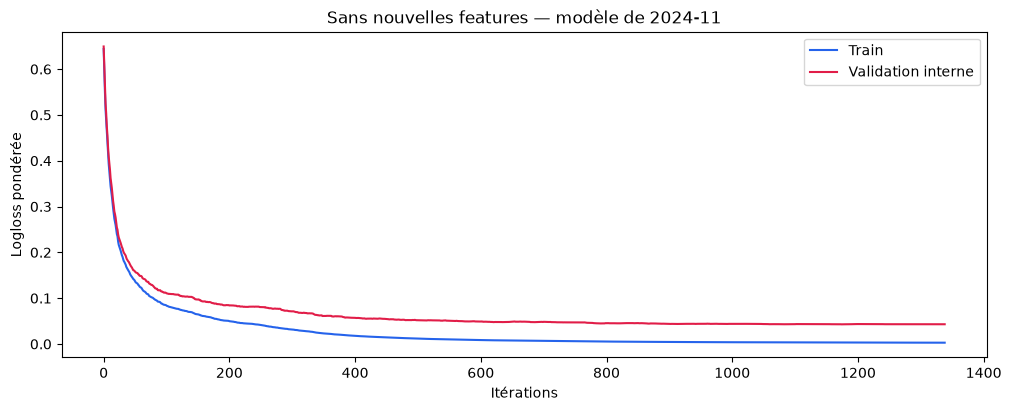

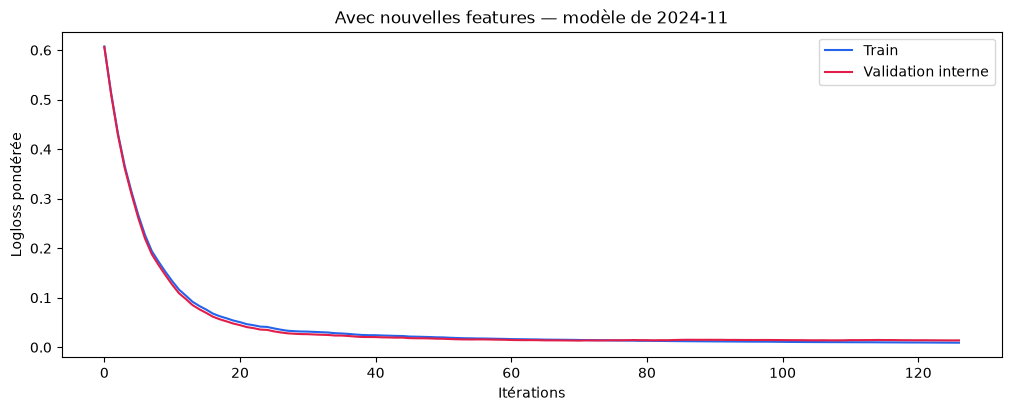

In [29]:
for experiment in experiments:
    plot_learning_curve(experiment, DISPLAY_MONTH)


## 2.7 — Matrices de confusion

Pour chaque modèle : validation juillet–septembre à gauche, test octobre–novembre à droite. Chaque expérience utilise son seuil choisi avant ses tests.


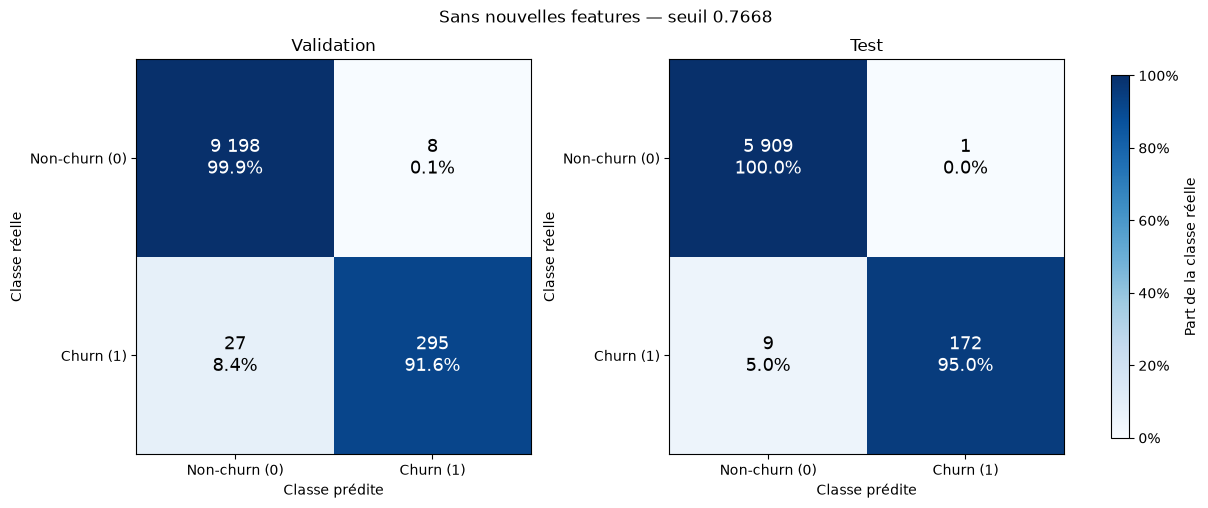

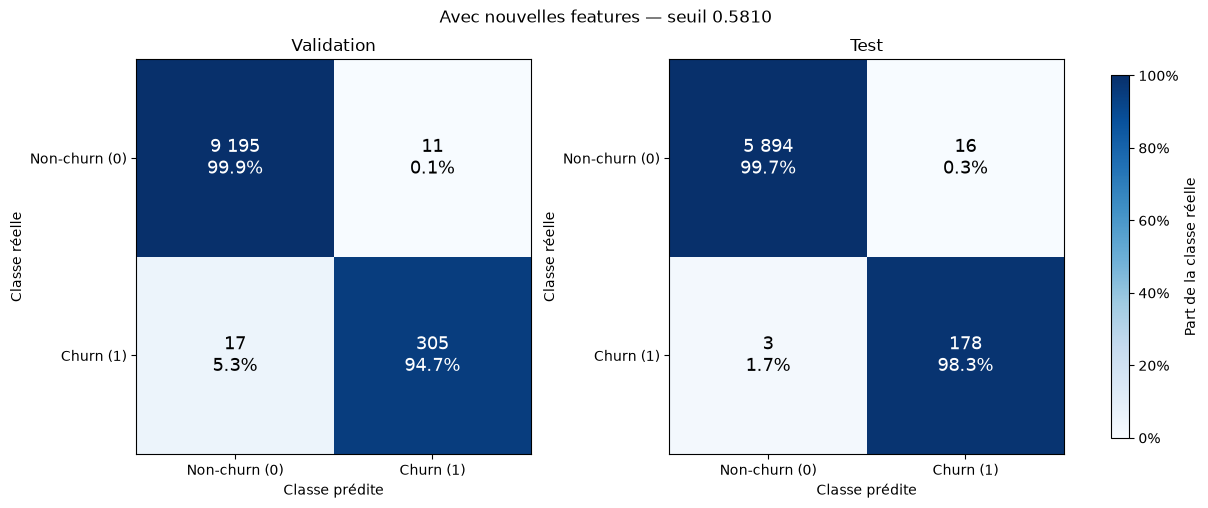

In [30]:
for experiment in experiments:
    plot_confusion_matrices(experiment)


## 2.8 — Importance de toutes les variables

Classement décroissant du dernier modèle mensuel de chaque expérience. Rouge : origine ; violet : créée. Une feature dominante doit être examinée avec sa disponibilité temporelle, ses corrélations et une ablation sur validation, sans forcer artificiellement un équilibre des importances.


,rank,feature,importance,source
0,1,monthly_fee,48.057590,Variable d’origine
1,2,last_invoice_amount,34.401430,Variable d’origine
2,3,data_gb,3.911004,Variable d’origine
3,4,contract,3.551872,Variable d’origine
4,5,support_calls_3m,3.537459,Variable d’origine
5,6,late_payments,2.941715,Variable d’origine
6,7,nps,1.940205,Variable d’origine
7,8,channel,1.658726,Variable d’origine


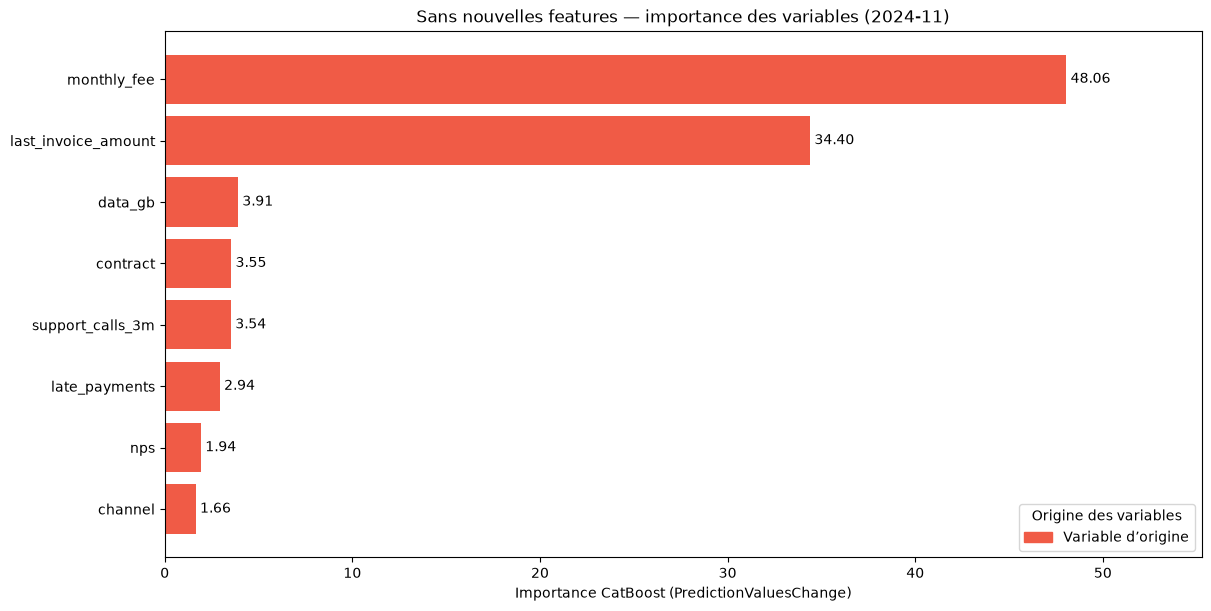

,rank,feature,importance,source
0,1,billing_deviation_pct,69.154537,Variable créée
1,2,contract,6.443917,Variable d’origine
2,3,last_invoice_amount,6.098950,Variable d’origine
3,4,monthly_fee,3.725517,Variable d’origine
4,5,support_calls_3m,3.497979,Variable d’origine
5,6,tenure_months,3.476041,Variable créée
6,7,nps,2.414263,Variable d’origine
7,8,support_payment_alert,2.053488,Variable créée
8,9,late_payment_alert,1.645064,Variable créée
9,10,usage_drop_pct,0.721424,Variable créée


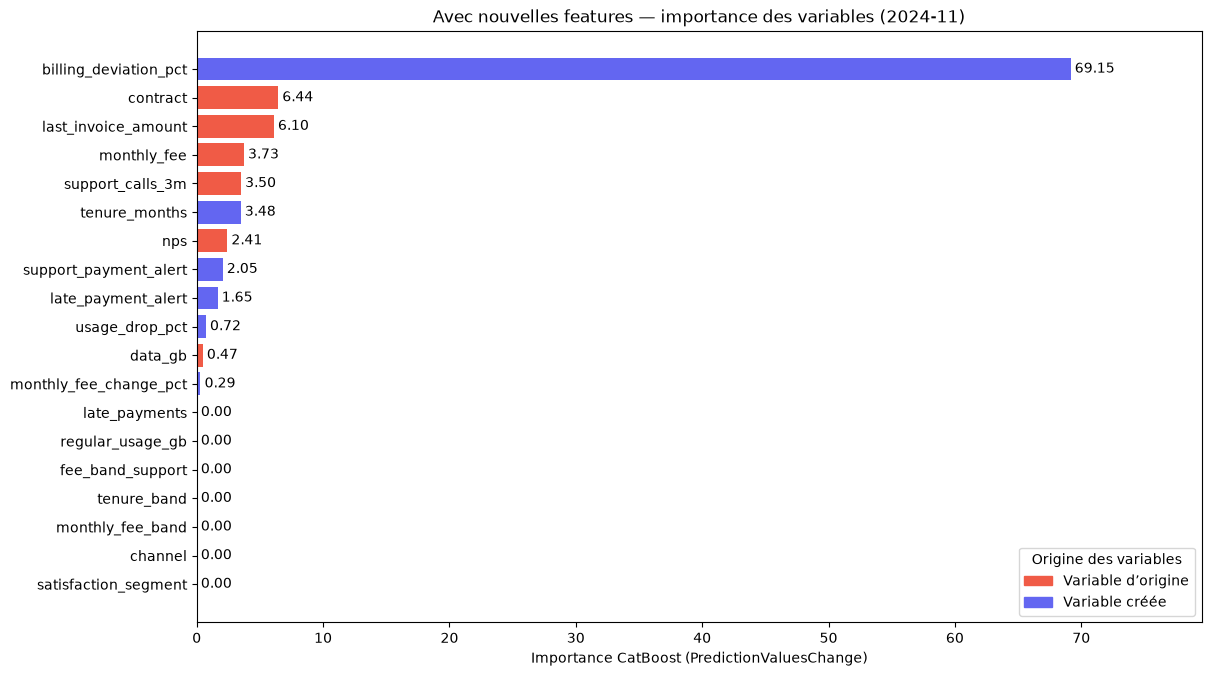

In [31]:
for experiment in experiments:
    plot_feature_importance(experiment, DISPLAY_MONTH)
